<a href="https://colab.research.google.com/github/Epidemic2001/PetProyects_Studies/blob/main/02_Machine_Learning/Ensemble_Learning/01_Bagging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio de Ensemble Learning con Breast Cancer Wisconsin

Este notebook utiliza el dataset real **Breast Cancer Wisconsin (Diagnostic)** incluido en `scikit-learn`.

- 569 observaciones.
- 30 variables numéricas.
- Variable objetivo binaria:
  - `0 = malignant`
  - `1 = benign`

El dataset se carga directamente desde `scikit-learn`, por lo que **no es necesario descargar un CSV externo**.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Cargar dataset real
data = load_wine(as_frame=True)

X = data.data
y = data.target

df = data.frame.copy()

print("Dimensiones:", df.shape)
print("\nClases:", list(data.target_names))
print("\nDistribución de clases:")
print(y.value_counts().sort_index())

df.head()

Dimensiones: (178, 14)

Clases: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]

Distribución de clases:
target
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## Exportación opcional del dataset

In [ ]:
# OPCIONAL: exportar el dataset a CSV
df.to_csv("wine.csv", index=False)

print("Archivo creado: wine.csv")

Archivo creado: wine.csv


## División train/test

In [ ]:
# Separación entrenamiento / prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (133, 13)
Test : (45, 13)


## 1. Modelo baseline: árbol de decisión

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

pred_tree = tree.predict(X_test)

print("Accuracy árbol:", accuracy_score(y_test, pred_tree))

Accuracy árbol: 0.9555555555555556


## 2. ¿Qué es Bootstrap?
El bootstrapping (o remuestreo bootstrap) es una técnica de muestreo estadístico utilizada en el aprendizaje automático para generar múltiples subconjuntos de datos diversos a partir de un único conjunto de entrenamiento inicial. Esta técnica es el núcleo y punto de partida del método de aprendizaje por conjuntos conocido como bagging (que significa Bootstrap Aggregating).

¿Cómo funciona el remuestreo bootstrap? El proceso de generación de estas muestras sigue una metodología sencilla pero muy efectiva:

1. Muestreo aleatorio con reemplazo: Si tienes un conjunto de datos original con
$n$ ejemplos de entrenamiento, se seleccionan puntos de datos al azar uno por uno hasta completar una nueva muestra de tamaño $n$.

2. Duplicación y exclusión de datos: Debido a que la selección es con reemplazo (es decir, cada elemento seleccionado se vuelve a colocar en el grupo para poder volver a ser elegido), un mismo dato puede aparecer repetido dos o más veces en la nueva muestra, mientras que otros datos originales quedarán completamente excluidos de ella. Las muestras resultantes de este proceso se conocen como muestras bootstrap.

3. Repetición: Este proceso se repite $x$ veces para producir $x$ iteraciones distintas del conjunto de datos original, cada una con características ligeramente diferentes.

Bagging genera distintas muestras del conjunto de entrenamiento **con reemplazo**.

Esto significa que algunos registros pueden aparecer varias veces y otros pueden quedar fuera de una muestra.

In [ ]:
np.random.seed(42)

ejemplo = np.arange(10)
muestra_bootstrap = np.random.choice(
    ejemplo,
    size=len(ejemplo),
    replace=True
)

print("Original :", ejemplo)
print("Bootstrap:", muestra_bootstrap)

Original : [0 1 2 3 4 5 6 7 8 9]
Bootstrap: [6 3 7 4 6 9 2 6 7 4]


## 3. Entrenamiento de Bagging

In [ ]:
from sklearn.ensemble import BaggingClassifier

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=5,
    max_samples=0.8,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

bagging.fit(X_train, y_train)

pred_bagging = bagging.predict(X_test)

print("Accuracy árbol  :", accuracy_score(y_test, pred_tree))
print("Accuracy Bagging:", accuracy_score(y_test, pred_bagging))

Accuracy árbol  : 0.9555555555555556
Accuracy Bagging: 0.9555555555555556


## 4. Efecto del número de estimadores

In [ ]:
n_estimators_values = [1,2,3,4,5,6,7,8,9,10]
accuracies = []

for n in n_estimators_values:
    model = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=n,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, prediction))

resultados_n = pd.DataFrame({
    "n_estimators": n_estimators_values,
    "accuracy": accuracies
})

resultados_n

,n_estimators,accuracy
0,1,0.955556
1,2,0.977778
2,3,1.000000
3,4,1.000000
4,5,1.000000
5,6,0.977778
6,7,1.000000
7,8,1.000000
8,9,1.000000
9,10,1.000000


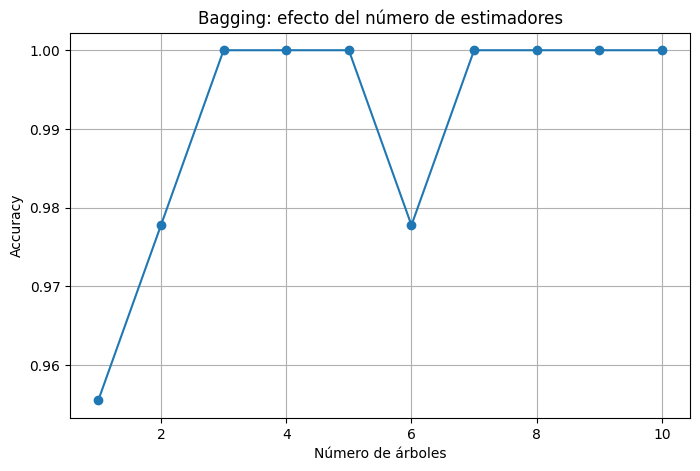

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(
    resultados_n["n_estimators"],
    resultados_n["accuracy"],
    marker="o"
)

plt.xlabel("Número de árboles")
plt.ylabel("Accuracy")
plt.title("Bagging: efecto del número de estimadores")
plt.grid()
plt.show()

## 5. Comparación de variabilidad: árbol vs Bagging

In [ ]:
tree_scores = []
bagging_scores = []

for seed in range(30):

    X_train_temp, X_test_temp, y_train_temp, y_test_temp = train_test_split(
        X,
        y,
        test_size=0.25,
        stratify=y,
        random_state=seed
    )

    tree_temp = DecisionTreeClassifier(random_state=seed)

    bag_temp = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=5,
        random_state=seed,
        n_jobs=-1
    )

    tree_temp.fit(X_train_temp, y_train_temp)
    bag_temp.fit(X_train_temp, y_train_temp)

    tree_scores.append(tree_temp.score(X_test_temp, y_test_temp))
    bagging_scores.append(bag_temp.score(X_test_temp, y_test_temp))

print("Desv. estándar árbol  :", np.std(tree_scores))
print("Desv. estándar Bagging:", np.std(bagging_scores))

Desv. estándar árbol  : 0.04174519349216407
Desv. estándar Bagging: 0.03413842554608271


/tmp/ipykernel_1650/3431523432.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


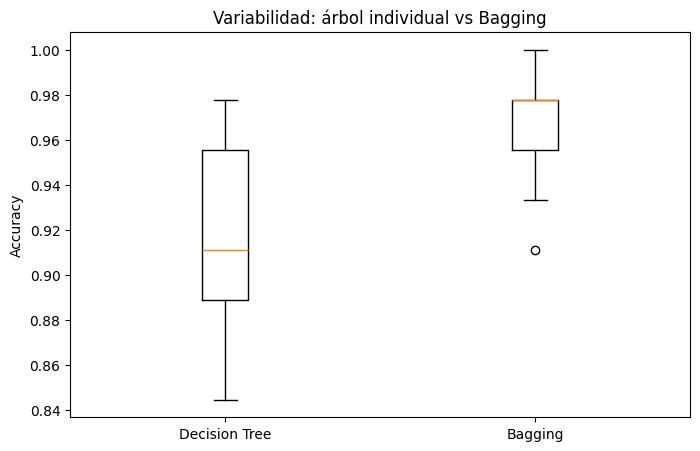

In [ ]:
plt.figure(figsize=(8,5))
plt.boxplot(
    [tree_scores, bagging_scores],
    labels=["Decision Tree", "Bagging"]
)

plt.ylabel("Accuracy")
plt.title("Variabilidad: árbol individual vs Bagging")
plt.show()

## 6. Métricas finales

In [ ]:
def evaluar_modelo(nombre, modelo, X_test, y_test):
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)

    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average='weighted'),
        "Recall": recall_score(y_test, pred, average='weighted'),
        "F1": f1_score(y_test, pred, average='weighted'),
        "ROC-AUC": roc_auc_score(y_test, prob, multi_class='ovr', average='weighted', labels=modelo.classes_)
    }

In [ ]:
resultados = pd.DataFrame([
    evaluar_modelo("Decision Tree", tree, X_test, y_test),
    evaluar_modelo("Bagging", bagging, X_test, y_test)
])

resultados

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Decision Tree,0.955556,0.960000,0.955556,0.955859,0.962963
1,Bagging,0.955556,0.958654,0.955556,0.955051,1.000000


## Preguntas de análisis

- ¿Mejoró el accuracy con Bagging?
- ¿Disminuyó la variabilidad?
- ¿Qué ocurre al aumentar de 50 a 100 o 200 árboles?
- ¿Por qué un conjunto de árboles puede ser más estable que un árbol individual?